**Name:** Aastha Kirtania  
**Roll No:** AP24110010038

# Week 10 Lab: Recommendation Systems (Content-Based and Collaborative Filtering)
**CSE303 Machine Learning | Unit: Recommender Systems | Syllabus: content-based filtering, collaborative filtering**

Pattern: **demo → practice → predict-then-run → deliberate error → reflection**, then an end-to-end **mini project** of your choice (handout: `Week10_Recsys_Project_Menu.docx`).

| Part | Topic | Track |
|---|---|---|
| 1 | The user × item rating matrix and sparsity | core |
| 2 | Content-based filtering (TF-IDF, cosine, user profile) | core |
| 3 | Collaborative filtering (user-based, item-based, mean-centering) | core |
| 4 | Evaluating a recommender (RMSE, precision@k, baselines, leakage) | core |
| 5 | Cold start and a simple hybrid | core |
| 6 | Mini project (end-to-end pipeline) | project |
| 7 | Reflection and capstone link | |

**Rule carried from Weeks 5 and 9:** split first. Anything learned from data (means, similarities, TF-IDF vocabulary) must be computed on **train only**.

**Why this week matters:** Netflix, YouTube, Amazon, Spotify, Swiggy and LinkedIn all run on recommenders. The two ideas you learn here (similar *items* by content, similar *users* by behaviour) are the foundation of every production system, including the deep-learning ones.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.precision', 3)
np.random.seed(1)


## Part 1: The Rating Matrix and Sparsity
A recommender starts from a table with one row per user and one column per item. Most cells are **empty** because nobody has watched everything. Predicting the empty cells is the whole problem.

Below: 12 films (each with a short text description) and 8 users who have rated a few of them (1 to 5).

In [2]:
movies = pd.DataFrame({
 'title':['Cricket Fever','Match Point','Spice Route','Curry Nights','Chip Wars','Quantum Phone',
          'Last Over','Pasta Masters','Robot Uprising','Boundary Line','Street Food Tales','Silicon Dreams'],
 'desc':['cricket team underdog sports tournament victory',
         'tennis rivalry sports championship coach athlete',
         'cooking travel spices chef kitchen street',
         'chef curry kitchen family restaurant cooking',
         'technology startup processor chips rivalry gadgets',
         'technology phone quantum science gadgets future',
         'cricket sports final over pressure team',
         'cooking pasta chef competition kitchen',
         'technology robot science future artificial',
         'cricket sports batsman boundary stadium',
         'cooking street food travel chef stories',
         'technology startup silicon gadgets future']})

users = ['Asha','Bala','Chitra','Dev','Esha','Farid','Gita','Hari']
data = {
 'Asha':  {'Cricket Fever':5,'Match Point':4,'Last Over':5,'Spice Route':1,'Chip Wars':2},
 'Bala':  {'Cricket Fever':5,'Boundary Line':4,'Match Point':5,'Pasta Masters':2,'Quantum Phone':1},
 'Chitra':{'Spice Route':5,'Curry Nights':5,'Pasta Masters':4,'Cricket Fever':1,'Robot Uprising':2},
 'Dev':   {'Curry Nights':4,'Street Food Tales':5,'Spice Route':4,'Last Over':2},
 'Esha':  {'Quantum Phone':5,'Chip Wars':4,'Robot Uprising':5,'Silicon Dreams':5,'Pasta Masters':1},
 'Farid': {'Chip Wars':5,'Silicon Dreams':4,'Quantum Phone':4,'Match Point':2},
 'Gita':  {'Cricket Fever':4,'Curry Nights':4,'Quantum Phone':4,'Street Food Tales':3,'Robot Uprising':3},
 'Hari':  {'Boundary Line':5,'Last Over':4,'Cricket Fever':5,'Spice Route':2,'Silicon Dreams':1},
}
R = pd.DataFrame(np.nan, index=users, columns=movies.title)
for u, d in data.items():
    for m, v in d.items():
        R.loc[u, m] = v
R


title,Cricket Fever,Match Point,Spice Route,Curry Nights,Chip Wars,Quantum Phone,Last Over,Pasta Masters,Robot Uprising,Boundary Line,Street Food Tales,Silicon Dreams
Asha,5.0,4.0,1.0,NaN,2.0,NaN,5.0,NaN,NaN,NaN,NaN,NaN
Bala,5.0,5.0,NaN,NaN,NaN,1.0,NaN,2.0,NaN,4.0,NaN,NaN
Chitra,1.0,NaN,5.0,5.0,NaN,NaN,NaN,4.0,2.0,NaN,NaN,NaN
Dev,NaN,NaN,4.0,4.0,NaN,NaN,2.0,NaN,NaN,NaN,5.0,NaN
Esha,NaN,NaN,NaN,NaN,4.0,5.0,NaN,1.0,5.0,NaN,NaN,5.0
Farid,NaN,2.0,NaN,NaN,5.0,4.0,NaN,NaN,NaN,NaN,NaN,4.0
Gita,4.0,NaN,NaN,4.0,NaN,4.0,NaN,NaN,3.0,NaN,3.0,NaN
Hari,5.0,NaN,2.0,NaN,NaN,NaN,4.0,NaN,NaN,5.0,NaN,1.0


In [3]:
n_ratings = int(R.notna().sum().sum())
print('ratings:', n_ratings, 'of', R.size, 'cells')
print('sparsity (share of empty cells):', round(1 - n_ratings / R.size, 3))


ratings: 38 of 96 cells
sparsity (share of empty cells): 0.604


**Predict, then think:** Netflix-scale data has millions of users and tens of thousands of titles. Would you expect the sparsity there to be *lower* or *higher* than here (60%)? What does that mean for methods that need two users to have rated the *same* items?

*Your answer:*

My guess: **higher**. At Netflix scale a typical user has rated or watched a tiny fraction of the catalogue, so sparsity is usually above 99%, not 60%. Methods that need two users to have rated the *same* items then rarely find enough overlap: similarities rest on one or two shared items (or none), so they are noisy or undefined. That is why large systems add content features, matrix factorization and cold-start fallbacks.

### Student Practice 1
1. How many ratings does each user have? Each movie?
2. Which movie has the most ratings (the most *popular*)? Which has the highest *average* rating? Are they the same movie?
3. Why is "most popular" a poor recommendation for every user, even though it is easy to compute?

In [4]:
per_user = R.notna().sum(axis=1)
per_movie = R.notna().sum(axis=0)
print('ratings per user :', per_user.to_dict())
print('ratings per movie:', per_movie.sort_values(ascending=False).to_dict())

stats = pd.DataFrame({'n_ratings': per_movie, 'avg_rating': R.mean()})
print()
print(stats.sort_values('n_ratings', ascending=False).head(5))
best_n, best_avg = stats.n_ratings.idxmax(), stats.avg_rating.idxmax()
print('\nmost popular   :', best_n, '(', int(stats.loc[best_n, 'n_ratings']), 'ratings, avg', round(stats.loc[best_n, 'avg_rating'], 2), ')')
print('highest average:', best_avg, '(', int(stats.loc[best_avg, 'n_ratings']), 'ratings, avg', round(stats.loc[best_avg, 'avg_rating'], 2), ')')


ratings per user : {'Asha': 5, 'Bala': 5, 'Chitra': 5, 'Dev': 4, 'Esha': 5, 'Farid': 4, 'Gita': 5, 'Hari': 5}
ratings per movie: {'Cricket Fever': 5, 'Spice Route': 4, 'Quantum Phone': 4, 'Match Point': 3, 'Curry Nights': 3, 'Chip Wars': 3, 'Last Over': 3, 'Pasta Masters': 3, 'Robot Uprising': 3, 'Silicon Dreams': 3, 'Boundary Line': 2, 'Street Food Tales': 2}

               n_ratings  avg_rating
title                               
Cricket Fever          5       4.000
Spice Route            4       3.000
Quantum Phone          4       3.500
Match Point            3       3.667
Curry Nights           3       4.333

most popular   : Cricket Fever ( 5 ratings, avg 4.0 )
highest average: Boundary Line ( 2 ratings, avg 4.5 )


**Answers (Practice 1)**
1. Every user rated 4 or 5 films (Dev and Farid 4, everyone else 5). Per film: Cricket Fever 5; Spice Route and Quantum Phone 4; Match Point, Curry Nights, Chip Wars, Last Over, Pasta Masters, Robot Uprising and Silicon Dreams 3; Boundary Line and Street Food Tales 2.
2. The most popular film is **Cricket Fever** (5 ratings, average 4.0). The highest average is **Boundary Line** (4.5, but from only 2 ratings). They are different films, and a 4.5 from two people is weak evidence.
3. "Most popular" is the same list for everyone, so it ignores taste. Chitra rated Cricket Fever 1 star, so it would be a bad recommendation for her. It also suggests films the user has already seen, and it feeds on itself, because recommended films get more ratings and become even more popular.

## Part 2: Content-Based Filtering
Idea: describe every **item** by its content, describe every **user** by the content of what they liked, and recommend items whose content matches the user's profile. Needs no other users.

Step 1: turn each description into a **TF-IDF** vector (words that appear in few items count more). Step 2: **cosine similarity** between items.

In [5]:
tfidf = TfidfVectorizer()
T = tfidf.fit_transform(movies.desc)           # items x words (sparse)
S_item = cosine_similarity(T)                   # items x items
titles = list(movies.title)

i = titles.index('Cricket Fever')
print(pd.Series(S_item[i], index=titles).sort_values(ascending=False).head(4))


Cricket Fever    1.000
Last Over        0.372
Boundary Line    0.237
Match Point      0.093
dtype: float64


**Predict, then think:** `Chip Wars` is a technology film about rivalry, and `Match Point` is a sports film about rivalry. Will they be more similar to each other than `Chip Wars` is to `Silicon Dreams`? Write your guess, then check it in the practice cell.

My guess: `Chip Wars` is **more similar to `Silicon Dreams`**. They share several words (technology, startup, gadgets), while `Match Point` shares only "rivalry", one word out of six. Checked in Practice 2: 0.457 against 0.152, so the guess was right.

### Student Practice 2
1. Print the similarity between `Chip Wars` and `Match Point`, and between `Chip Wars` and `Silicon Dreams`. Was your guess right?
2. Which 3 films are most similar to `Spice Route`?

In [6]:
i = titles.index('Chip Wars')
print('Chip Wars vs Match Point    :', round(S_item[i, titles.index('Match Point')], 3))
print('Chip Wars vs Silicon Dreams :', round(S_item[i, titles.index('Silicon Dreams')], 3))

j = titles.index('Spice Route')
print('\nMost similar to Spice Route:')
print(pd.Series(S_item[j], index=titles).drop('Spice Route').sort_values(ascending=False).head(3))


Chip Wars vs Match Point    : 0.152
Chip Wars vs Silicon Dreams : 0.457

Most similar to Spice Route:
Street Food Tales    0.574
Pasta Masters        0.403
Curry Nights         0.355
dtype: float64


**Answers (Practice 2)**
1. Chip Wars vs Match Point = **0.152**; Chip Wars vs Silicon Dreams = **0.457**. My guess was right: a shared genre (several shared words) matters far more than one shared theme word.
2. Closest to Spice Route: **Street Food Tales (0.574), Pasta Masters (0.403), Curry Nights (0.355)**, all cooking films.

### Building a user profile
A user profile is a weighted sum of the vectors of the items they rated. We weight by **rating minus the user's own average**, so a 1-star film pushes the profile *away* from its content and a 5-star film pulls it *toward* it. Then we score unseen items by cosine similarity to the profile.

In [7]:
def user_profile(u):
    r = R.loc[u].dropna()
    w = r - r.mean()                                   # mean-centred weights
    idx = [titles.index(m) for m in r.index]
    return np.asarray(T[idx].T.dot(w.values)).ravel()

def recommend_cb(u, n=3):
    p = user_profile(u)
    scores = pd.Series(cosine_similarity(p.reshape(1, -1), T).ravel(), index=titles)
    return scores[R.loc[u].isna()].sort_values(ascending=False).head(n)   # unseen only

print('Asha:\n', recommend_cb('Asha'))


Asha:
 Boundary Line     0.210
Robot Uprising   -0.040
Quantum Phone    -0.084
dtype: float64


### Student Practice 3
1. Recommend 3 films for `Gita` (she likes sports, cooking and tech). Do the scores look confident? Why or why not?
2. Which of Asha's ratings pulls her profile *away* from cooking content? (Look at the weights `r - r.mean()`.)

In [8]:
print('Gita:')
print(recommend_cb('Gita'))

for u in ['Gita', 'Asha']:
    r = R.loc[u].dropna()
    print(f'\n{u}: mean = {r.mean():.2f}; weights r - mean:')
    print((r - r.mean()).sort_values().round(2).to_dict())


Gita:
Last Over        0.158
Boundary Line    0.100
Match Point      0.039
dtype: float64

Gita: mean = 3.60; weights r - mean:
{'Robot Uprising': -0.6, 'Street Food Tales': -0.6, 'Curry Nights': 0.4, 'Cricket Fever': 0.4, 'Quantum Phone': 0.4}

Asha: mean = 3.40; weights r - mean:
{'Spice Route': -2.4, 'Chip Wars': -1.4, 'Match Point': 0.6, 'Cricket Fever': 1.6, 'Last Over': 1.6}


**Answers (Practice 3)**
1. Gita's top 3 are `Last Over` (0.158), `Boundary Line` (0.100) and `Match Point` (0.039). The scores are **not confident**: all are low. Gita rated sports, cooking and tech films, and her mean-centred weights are small (+0.4 for her three 4-star films, -0.6 for her two 3-star films) and point in different content directions. The profile is a muddle of three genres with no strong direction, so no unseen film matches it well. The few sports titles on top come only from the +0.4 on Cricket Fever.
2. Asha's mean is 3.4. `Spice Route` (1 star) has weight **-2.4**, the largest negative, so it pushes her profile hardest away from cooking content. `Chip Wars` (2 stars, -1.4) pushes her away from tech.

### Deliberate error 1: forgetting to mean-centre
Run the cell, then answer: why does this version recommend things Asha would dislike?

In [9]:
def recommend_cb_raw(u, n=3):
    r = R.loc[u].dropna()                              # WRONG: raw ratings as weights
    idx = [titles.index(m) for m in r.index]
    p = np.asarray(T[idx].T.dot(r.values)).ravel()
    s = pd.Series(cosine_similarity(p.reshape(1, -1), T).ravel(), index=titles)
    return s[R.loc[u].isna()].sort_values(ascending=False).head(n)

print('Asha, WRONG (raw weights):\n', recommend_cb_raw('Asha'))
print('Asha, correct (centred)  :\n', recommend_cb('Asha'))


Asha, WRONG (raw weights):
 Boundary Line        0.278
Silicon Dreams       0.092
Street Food Tales    0.058
dtype: float64
Asha, correct (centred)  :
 Boundary Line     0.210
Robot Uprising   -0.040
Quantum Phone    -0.084
dtype: float64


*Your answer (one line):*

The raw version uses ratings as weights, so every film the user rated, even the 1-star `Spice Route`, adds its content to the profile. Her dislike becomes a vote *for* cooking, and the raw list includes the cooking film `Street Food Tales`. Centring turns dislikes into negative weights that push away from that content.

## Part 3: Collaborative Filtering
Idea: **ignore content entirely**. Find users who rate like you and recommend what they liked. Works for any item type (a song, a job, a drug), but needs overlapping ratings.

Key steps for **user-based** CF:
1. Mean-centre each user's ratings (a harsh rater's 4 equals a generous rater's 5).
2. Compute user-user similarity on the centred matrix.
3. Predict: $\hat r_{u,m}=\bar r_u+\dfrac{\sum_{v} sim(u,v)\,(r_{v,m}-\bar r_v)}{\sum_{v}|sim(u,v)|}$ over the top-k similar users who rated $m$.

In [10]:
def build_user_cf(R_train):
    means = R_train.mean(axis=1)
    C = R_train.sub(means, axis=0).fillna(0)            # centred; unrated -> 0 = "no opinion"
    sim = pd.DataFrame(cosine_similarity(C), index=R_train.index, columns=R_train.index)
    return means, sim

def predict_user_cf(R_train, means, sim, u, m, k=3):
    raters = R_train[m].dropna().index.difference([u])
    if len(raters) == 0:
        return means[u]                                  # nobody rated it: fall back to user mean
    s = sim.loc[u, raters].sort_values(ascending=False).head(k)
    s = s[s > 0]
    if len(s) == 0:
        return means[u]
    return means[u] + (s * (R_train.loc[s.index, m] - means[s.index])).sum() / s.abs().sum()

means, sim_u = build_user_cf(R)
print(sim_u.round(2))
print()
print('Asha  -> Boundary Line :', round(predict_user_cf(R, means, sim_u, 'Asha', 'Boundary Line'), 2))
print('Gita  -> Pasta Masters :', round(predict_user_cf(R, means, sim_u, 'Gita', 'Pasta Masters'), 2))


        Asha  Bala  Chitra   Dev  Esha  Farid  Gita  Hari
Asha    1.00  0.27   -0.58 -0.43  0.00  -0.35  0.16  0.52
Bala    0.27  1.00   -0.35  0.00  0.14  -0.43 -0.08  0.27
Chitra -0.58 -0.35    1.00  0.10 -0.25   0.00  0.13 -0.46
Dev    -0.43  0.00    0.10  1.00  0.00   0.00 -0.27 -0.18
Esha    0.00  0.14   -0.25  0.00  1.00   0.07 -0.05 -0.19
Farid  -0.35 -0.43    0.00  0.00  0.07   1.00  0.04 -0.08
Gita    0.16 -0.08    0.13 -0.27 -0.05   0.04  1.00  0.16
Hari    0.52  0.27   -0.46 -0.18 -0.19  -0.08  0.16  1.00

Asha  -> Boundary Line : 4.66
Gita  -> Pasta Masters : 4.2


**Predict, then think:** Asha and Hari both love cricket films. Their similarity above should be the largest positive value in Asha's row. Is it? And what sign do you expect between Asha and Chitra (cooking fan who disliked `Cricket Fever`)?

My guess, checked in the table above: yes. Asha-Hari = **0.52** is the largest positive value in Asha's row (next is Bala at 0.27). Asha-Chitra is strongly **negative** (-0.58, the most negative in the row), since Chitra loves cooking and rated `Cricket Fever` 1 star.

### Student Practice 4
1. List the 3 most similar users to `Asha` and the 3 *least* similar. Do they match your intuition?
2. Predict `Esha -> Match Point` and `Dev -> Cricket Fever`. For each, which users were used?
3. **Item-based CF:** build item-item similarity from the *centred* matrix (centre by user, then take cosine between *columns*) and predict `Asha -> Boundary Line` as the similarity-weighted average of Asha's own ratings on the most similar rated items. Compare with the user-based answer.

In [11]:
# 1. Most and least similar users to Asha
row = sim_u.loc['Asha'].drop('Asha').sort_values(ascending=False)
print('3 most similar :', row.head(3).round(2).to_dict())
print('3 least similar:', row.tail(3).round(2).to_dict())

# 2. Which neighbours produced each prediction?
for u, m in [('Esha', 'Match Point'), ('Dev', 'Cricket Fever')]:
    raters = R[m].dropna().index.difference([u])
    s = sim_u.loc[u, raters].sort_values(ascending=False).head(3)
    used = s[s > 0]
    print(f'\n{u} -> {m}: prediction {predict_user_cf(R, means, sim_u, u, m):.2f}')
    print('  all raters and similarity:', sim_u.loc[u, raters].round(2).to_dict())
    print('  neighbours used          :', used.round(2).to_dict())

# 3. Item-based CF: centre by user, cosine between COLUMNS
def build_item_cf(R_train):
    means = R_train.mean(axis=1)
    Cc = R_train.sub(means, axis=0).fillna(0)
    sim = pd.DataFrame(cosine_similarity(Cc.T), index=R_train.columns, columns=R_train.columns)
    return means, sim

def predict_item_cf(R_train, means, sim_i, u, m, k=3):
    rated = R_train.loc[u].dropna().index.difference([m])      # the user's OWN rated items
    if len(rated) == 0:
        return means[u]
    s = sim_i.loc[m, rated].sort_values(ascending=False).head(k)
    s = s[s > 0]
    if len(s) == 0:
        return means[u]
    return means[u] + (s * (R_train.loc[u, s.index] - means[u])).sum() / s.abs().sum()

means_i0, sim_i0 = build_item_cf(R)
s = sim_i0.loc['Boundary Line', R.loc['Asha'].dropna().index].sort_values(ascending=False)
print('\nItems Asha rated, by similarity to Boundary Line:', s.round(3).to_dict())
print('Item-CF  Asha -> Boundary Line:', round(predict_item_cf(R, means_i0, sim_i0, 'Asha', 'Boundary Line'), 2))
print('User-CF  Asha -> Boundary Line:', round(predict_user_cf(R, means, sim_u, 'Asha', 'Boundary Line'), 2))


3 most similar : {'Hari': 0.52, 'Bala': 0.27, 'Gita': 0.16}
3 least similar: {'Farid': -0.35, 'Dev': -0.43, 'Chitra': -0.58}

Esha -> Match Point: prediction 4.54
  all raters and similarity: {'Asha': 0.0, 'Bala': 0.14, 'Farid': 0.07}
  neighbours used          : {'Bala': 0.14, 'Farid': 0.07}

Dev -> Cricket Fever: prediction 1.35
  all raters and similarity: {'Asha': -0.43, 'Bala': 0.0, 'Chitra': 0.1, 'Gita': -0.27, 'Hari': -0.18}
  neighbours used          : {'Chitra': 0.1}

Items Asha rated, by similarity to Boundary Line: {'Cricket Fever': 0.559, 'Match Point': 0.23, 'Last Over': 0.23, 'Chip Wars': 0.0, 'Spice Route': -0.408}
Item-CF  Asha -> Boundary Line: 4.77
User-CF  Asha -> Boundary Line: 4.66


**Answers (Practice 4)**
1. Most similar to Asha: **Hari (0.52), Bala (0.27), Gita (0.16)**. Least similar: **Chitra (-0.58), Dev (-0.43), Farid (-0.35)**. This matches intuition: Hari and Bala are the cricket fans, while Chitra and Dev are cooking-leaning and Farid is the tech fan who rated `Match Point` low.
2. **Esha -> Match Point = 4.54**, from Bala (0.14) and Farid (0.07). Asha also rated it, but her similarity to Esha is 0, so she is dropped by `s > 0`. **Dev -> Cricket Fever = 1.35**, from **Chitra only** (0.10); Asha, Gita and Hari have negative similarity to Dev and Bala has 0. Chitra's 1 star is 2.4 below her mean, and Dev's mean is 3.75, so 3.75 - 2.4 = 1.35.
3. Item-CF gives **Asha -> Boundary Line = 4.77** (neighbours: Cricket Fever 0.559, Match Point 0.23, Last Over 0.23; Chip Wars is 0 and Spice Route negative, so both are dropped). User-CF gave **4.66**. Both say Asha will love it. They differ slightly because user-CF uses her neighbours' opinions of Boundary Line (Bala and Hari), while item-CF uses her own ratings of similar films. With all positive similarities, the centred and the plain weighted average give the same number.

### Deliberate error 2: treating "unrated" as "rated 0"
Run the cell. Compare the two similarity rows for Asha. Why is filling gaps with 0 on the *raw* matrix wrong?

In [12]:
sim_raw0 = pd.DataFrame(cosine_similarity(R.fillna(0)), index=users, columns=users)   # WRONG
print('raw, gaps=0 :', sim_raw0.loc['Asha'].drop('Asha').round(2).to_dict())
print('centred     :', sim_u.loc['Asha'].drop('Asha').round(2).to_dict())


raw, gaps=0 : {'Bala': 0.63, 'Chitra': 0.14, 'Dev': 0.21, 'Esha': 0.1, 'Farid': 0.27, 'Gita': 0.29, 'Hari': 0.66}
centred     : {'Bala': 0.27, 'Chitra': -0.58, 'Dev': -0.43, 'Esha': 0.0, 'Farid': -0.35, 'Gita': 0.16, 'Hari': 0.52}


*Your answer (one or two lines):*

Filling gaps with 0 on the raw matrix makes every similarity positive (0.10 to 0.66). Chitra, who has the opposite taste, comes out at +0.14 instead of -0.58, and Dev at +0.21 instead of -0.43. A 0 is treated as a real opinion (worse than the lowest 1-star rating), and since all real ratings are positive, the dot products are positive anyway; similarity then mostly reflects how many films people rated, not whether they agree. Centring first makes "unrated" a neutral 0 and lets disagreement become negative.

## Part 4: Evaluating a Recommender
You cannot judge a recommender on ratings it has already seen. **Hold out some known ratings, hide them, predict them, compare.**

- **RMSE** for rating prediction: $\sqrt{\frac1n\sum(\hat r-r)^2}$. Lower is better.
- Always compare with **baselines**: the global mean, and each user's own mean. A model that cannot beat these is not learning anything useful.

Our toy matrix has only 38 ratings, too few to evaluate honestly. So we switch to a **generated** dataset with the same structure: 60 users, 30 films in three genres, about 35% of cells observed, and each user having a favourite genre. (In your project you will use real data.)

In [13]:
def make_data(n_users=60, n_items=30, density=0.35, seed=1):
    rng = np.random.RandomState(seed)
    vocab = {'sports':  ['cricket','match','team','stadium','batsman','tennis','coach','tournament'],
             'cooking': ['chef','kitchen','curry','pasta','spices','restaurant','recipe','street'],
             'tech':    ['phone','processor','startup','gadgets','robot','battery','laptop','science']}
    genres, common = list(vocab), ['new','story','family','final','night','world']
    names = [f'Film{i:02d}' for i in range(n_items)]
    g_item = [genres[i % 3] for i in range(n_items)]
    desc = [' '.join(list(rng.choice(vocab[g], 3, replace=False)) + list(rng.choice(common, 1))) for g in g_item]
    ub, ib = rng.normal(0, 0.3, n_users), rng.normal(0, 0.2, n_items)
    fav = rng.randint(0, 3, n_users)
    Rb = pd.DataFrame(np.nan, index=[f'U{u:02d}' for u in range(n_users)], columns=names)
    for u in range(n_users):
        for i in range(n_items):
            if rng.rand() < density:
                aff = 1.6 if genres.index(g_item[i]) == fav[u] else -1.0
                r = 3 + aff + ub[u] + ib[i] + rng.normal(0, 0.5)
                Rb.iloc[u, i] = float(np.clip(np.round(r), 1, 5))
    return Rb, pd.DataFrame({'title': names, 'desc': desc, 'genre': g_item})

Rb, items = make_data()
print('ratings:', int(Rb.notna().sum().sum()), '| sparsity:', round(1 - Rb.notna().sum().sum() / Rb.size, 3))
print('fewest ratings by one user:', int(Rb.notna().sum(axis=1).min()))
items.head(4)


ratings: 609 | sparsity: 0.662
fewest ratings by one user: 4


,title,desc,genre
0,Film00,tournament team match world,sports
1,Film01,curry pasta spices story,cooking
2,Film02,processor laptop gadgets night,tech
3,Film03,cricket tournament match new,sports


In [14]:
# Content similarity for the generated films, as a labelled table (rows/cols = film names)
tfidf_b = TfidfVectorizer().fit(items.desc)
Tb = tfidf_b.transform(items.desc)
S_b = pd.DataFrame(cosine_similarity(Tb), index=items.title, columns=items.title)

def predict_cb(R_train, S, u, m, k=3):
    """Content-based rating prediction: user's mean + similarity-weighted centred ratings of content-similar rated items."""
    rated = R_train.loc[u].dropna().index.difference([m])
    sims = S.loc[m, rated].sort_values(ascending=False).head(k)
    sims = sims[sims > 0]
    mu = R_train.loc[u].mean()
    if len(sims) == 0:
        return mu
    return mu + (sims * (R_train.loc[u, sims.index] - mu)).sum() / sims.abs().sum()

def rmse(pred, true):
    pred, true = np.array(pred), np.array(true)
    return float(np.sqrt(np.mean((pred - true) ** 2)))

# hold out 20% of the known ratings (split the RATINGS, not the users)
rng = np.random.RandomState(1)
pairs = [(u, m) for u in Rb.index for m in Rb.columns if not np.isnan(Rb.loc[u, m])]
test_pairs = [pairs[i] for i in rng.choice(len(pairs), size=int(0.2 * len(pairs)), replace=False)]
Rb_train = Rb.copy()
for u, m in test_pairs:
    Rb_train.loc[u, m] = np.nan                                   # hide the test ratings
true = [Rb.loc[u, m] for u, m in test_pairs]
print('train ratings:', int(Rb_train.notna().sum().sum()), '| test ratings:', len(test_pairs))

means_tr, sim_tr = build_user_cf(Rb_train)                        # fitted on TRAIN only
gmean = np.nanmean(Rb_train.values)

p_global = [gmean for _ in test_pairs]
p_user   = [means_tr[u] for u, m in test_pairs]
p_cf     = [predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=5) for u, m in test_pairs]

print('RMSE global mean :', round(rmse(p_global, true), 3))
print('RMSE user mean   :', round(rmse(p_user, true), 3))
print('RMSE user-CF k=5 :', round(rmse(p_cf, true), 3))


train ratings: 488 | test ratings: 121


RMSE global mean : 1.354
RMSE user mean   : 1.499
RMSE user-CF k=5 : 1.169


**Predict, then think:** the user-mean baseline can be *worse* than the global mean. Why might that happen when each user has only about 10 ratings, and the user's ratings come mostly from their favourite or least-favourite genre?

*Your answer:*

The user mean is estimated from very few ratings, and those ratings come mostly from the user's favourite genre (about 4 to 5 stars) or least favourite genre (about 1 to 2 stars). It is a noisy mixture that predicts neither: a user whose ratings mostly came from the favourite genre has an inflated mean, and then their disliked-genre test ratings miss by a lot. The global mean uses all 488 training ratings, so it has low variance. Here the user mean (1.499) is indeed worse than the global mean (1.354).

### Student Practice 5
1. Add **item-based CF** (reuse `predict_item_cf`, with an item-item similarity built from `Rb_train` only) and **content-based** (`predict_cb` with `S_b`). Report RMSE for all five methods in one table.
2. Try `k` in [1, 3, 5, 10, 20] for user-CF. Plot RMSE against k. Which k would you pick? What happens at k=1?
3. **Precision@3:** for each user with at least one held-out rating of 4 or more, recommend the top 3 unseen items by user-CF prediction (using `Rb_train`); count how many of that user's held-out high ratings appear in the top 3. Report the mean over those users.

                      RMSE
global mean          1.354
user mean            1.499
user-CF (k=5)        1.169
item-CF (k=5)        1.070
content-based (k=5)  1.135



user-CF RMSE by k: {1: np.float64(1.356), 3: np.float64(1.203), 5: np.float64(1.169), 10: np.float64(1.179), 20: np.float64(1.18)}


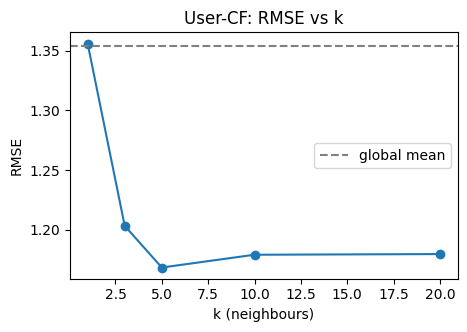


Precision@3 = 0.204 over 31 users


In [15]:
# 1. All five methods in one table (everything built from Rb_train only)
means_i, sim_i = build_item_cf(Rb_train)
p_icf = [predict_item_cf(Rb_train, means_i, sim_i, u, m, k=5) for u, m in test_pairs]
p_cb  = [predict_cb(Rb_train, S_b, u, m, k=5) for u, m in test_pairs]

results = pd.DataFrame({'RMSE': {'global mean': rmse(p_global, true), 'user mean': rmse(p_user, true),
                                 'user-CF (k=5)': rmse(p_cf, true), 'item-CF (k=5)': rmse(p_icf, true),
                                 'content-based (k=5)': rmse(p_cb, true)}}).round(3)
print(results)

# 2. RMSE against k for user-CF
ks = [1, 3, 5, 10, 20]
rm_k = []
for k in ks:
    p = [predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=k) for u, m in test_pairs]
    rm_k.append(rmse(p, true))
print('\nuser-CF RMSE by k:', dict(zip(ks, np.round(rm_k, 3))))
plt.figure(figsize=(5, 3.2))
plt.plot(ks, rm_k, marker='o')
plt.axhline(rmse(p_global, true), color='grey', ls='--', label='global mean')
plt.xlabel('k (neighbours)'); plt.ylabel('RMSE'); plt.title('User-CF: RMSE vs k'); plt.legend(); plt.show()

# 3. Precision@3 (hit = held-out rating >= 4 that appears in the user's top 3 unseen items)
prec = []
for u in Rb.index:
    liked = {m for (uu, m) in test_pairs if uu == u and Rb.loc[u, m] >= 4}
    if not liked:
        continue
    unseen = Rb_train.columns[Rb_train.loc[u].isna()]          # includes the hidden test items
    scores = pd.Series({m: predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=5) for m in unseen})
    top3 = set(scores.sort_values(ascending=False).head(3).index)
    prec.append(len(top3 & liked) / 3)
print('\nPrecision@3 =', round(np.mean(prec), 3), 'over', len(prec), 'users')


**Answers (Practice 5)**
1. RMSE on the 121 held-out ratings: global mean **1.354**, user mean **1.499**, user-CF **1.169**, content-based **1.135**, item-CF **1.070**. Item-CF is best; every personalised method beats both baselines, and the user mean is the worst.
2. user-CF RMSE: k=1 **1.356**, k=3 1.203, k=5 **1.169**, k=10 1.179, k=20 1.180. I would pick **k=5**, the lowest, although k=10 and 20 are almost the same. At k=1 the prediction rests on a single neighbour's opinion, so it is very noisy (RMSE about the same as the global mean).
3. **Precision@3 = 0.204** over 31 users (precision = hits in the top 3 divided by 3). That is low in absolute terms, but the ceiling is small: 25 of the 31 users have exactly one held-out liked film (the other 6 have two), so for most users precision@3 can only be 0 or 0.33. The held-out ratings are also only a few of the films a user would actually like.

### Deliberate error 3: data leakage
The cell below computes the user similarities and means from the **full** matrix (including the hidden test ratings), then "predicts" them. Run it, compare with the honest RMSE above, and explain the gap. Would this error be visible if you only looked at the final number?

In [16]:
means_leak, sim_leak = build_user_cf(Rb)                       # WRONG: sees the test ratings
p_leak = [predict_user_cf(Rb_train, means_leak, sim_leak, u, m, k=5) for u, m in test_pairs]
print('leaky RMSE :', round(rmse(p_leak, true), 3))
print('honest RMSE:', round(rmse(p_cf, true), 3))


leaky RMSE : 0.621
honest RMSE: 1.169


*Your answer (one or two lines):*

The leaky RMSE is **0.621** against the honest **1.169**, almost half. The means and similarities were built from the full matrix, so the user's own mean already contains the hidden rating, and the user-user similarities were computed using that very rating, which pulls in neighbours who agree on it. The model has seen the answer. No, you could not tell from the number alone: 0.62 just looks like a great model. You only catch it by checking what data each step was fitted on, which is why the split must come before any means, similarities or TF-IDF.

## Part 5: Cold Start and a Simple Hybrid
- **New user** (no ratings): CF has nothing to compare. **New item** (no ratings): CF cannot score it. Content-based can handle a new *item* because it only needs the description.
- A **hybrid** blends both: $\hat r = \alpha\,\hat r_{CF}+(1-\alpha)\,\hat r_{CB}$.

In [17]:
# A brand-new film: we know its text, nobody has rated it
new_desc = 'cricket match stadium team new'
sims_new = pd.Series(cosine_similarity(tfidf_b.transform([new_desc]), Tb).ravel(), index=items.title)
print('New film is most similar to:', list(sims_new.sort_values(ascending=False).head(3).index))
print('Their genres:', [items.set_index('title').genre[t] for t in sims_new.sort_values(ascending=False).head(3).index])


New film is most similar to: ['Film15', 'Film03', 'Film24']
Their genres: ['sports', 'sports', 'sports']


### Student Practice 6
1. Compute hybrid RMSE for $\alpha \in \{0, 0.25, 0.5, 0.75, 1\}$ using `p_cf` and `p_cb`. Which blend is best?
2. A user signs up and has rated **nothing**. Write a fallback recommender (hint: highest average rating among items with at least 3 ratings). State one weakness.
3. A brand-new film has **zero** ratings. Which of the three models (user-CF, item-CF, content-based) can still score it, and why?

In [18]:
# 1. Hybrid RMSE: alpha * CF + (1 - alpha) * CB
alphas = [0, 0.25, 0.5, 0.75, 1]
hyb = {a: rmse([a * x + (1 - a) * y for x, y in zip(p_cf, p_cb)], true) for a in alphas}
print({a: round(v, 3) for a, v in hyb.items()})
print('best alpha:', min(hyb, key=hyb.get))

# 2. Cold-start user: best average rating among items with at least 3 ratings
def recommend_new_user(R_train, n=3, min_ratings=3):
    cnt, avg = R_train.notna().sum(), R_train.mean()
    return avg[cnt >= min_ratings].sort_values(ascending=False).head(n)
fallback = recommend_new_user(Rb_train)
print('\nFallback for a user with no ratings:')
print(pd.DataFrame({'avg': fallback.round(2), 'genre': items.set_index('title').genre[fallback.index]}))

# 3. Cold-start item: add a film with zero ratings and see what each model can do
Rb_new = Rb_train.copy(); Rb_new['NewFilm'] = np.nan
u = 'U00'
means_n, sim_un = build_user_cf(Rb_new)
means_n2, sim_in = build_item_cf(Rb_new)
mu = Rb_new.loc[u].mean()
print('\nU00 mean rating                  :', round(mu, 3))
print('user-CF  on the new film          :', round(predict_user_cf(Rb_new, means_n, sim_un, u, 'NewFilm'), 3), '(just the user mean)')
print('item-CF  on the new film          :', round(predict_item_cf(Rb_new, means_n2, sim_in, u, 'NewFilm'), 3), '(just the user mean)')
rated = Rb_new.loc[u].dropna().index
s = sims_new[rated].sort_values(ascending=False).head(3); s = s[s > 0]
print('content-based on the new film     :', round(mu + (s * (Rb_new.loc[u, s.index] - mu)).sum() / s.abs().sum(), 3), 'using', list(s.index))


{0: 1.135, 0.25: 1.1, 0.5: 1.093, 0.75: 1.117, 1: 1.169}
best alpha: 0.5

Fallback for a user with no ratings:
         avg   genre
Film11  3.50    tech
Film12  3.25  sports
Film05  3.20    tech

U00 mean rating                  : 3.364
user-CF  on the new film          : 3.364 (just the user mean)
item-CF  on the new film          : 3.364 (just the user mean)
content-based on the new film     : 4.631 using ['Film24', 'Film21', 'Film27']


**Answers (Practice 6)**
1. Hybrid RMSE: alpha=0 **1.135**, 0.25 **1.100**, 0.5 **1.093**, 0.75 1.117, 1 1.169. The best blend is **alpha = 0.5**, better than either model alone, because the two models' errors are partly independent and average out. (Item-CF alone, 1.070, is better still, so a CF + CB hybrid is not automatically the best choice.)
2. The fallback recommends the highest-average films that have at least 3 ratings (the code output shows the top 3). **Weakness:** it is the same list for everyone, so it is not personalised. It is also based on very few ratings per film, so the averages are noisy, and it leaves out new films that are not yet rated.
3. Only **content-based** can really score a brand-new film, because it needs just the description to find similar rated films. User-CF finds no raters and item-CF finds no usable similarities (the new film's column is all zeros), so both fall back to the user's mean, which is the same score for every unrated film and cannot rank them.

## Part 6: Mini Project (End-to-End Pipeline)
Before the project, one warm-up that you will repeat on your own data.

### Student Practice 7: the by-hand check
AI tools can write a recommender in minutes. What they cannot do is make *you* understand it. In your project you must reproduce **one prediction by hand** and show that your code gives the same number. Practise here:

`Esha -> Match Point` was predicted from her two positive-similarity neighbours, Bala (similarity 0.14) and Farid (0.07). Using only the ratings table and those two similarities, compute the prediction on paper with the user-based formula from Part 3, then compare with the code. Why is there a small difference?

In [19]:
# By-hand check: Esha -> Match Point
mu_esha = means['Esha']
bala, farid = ('Bala', 'Farid')
s_b, s_f = sim_u.loc['Esha', bala], sim_u.loc['Esha', farid]
dev_b = R.loc[bala, 'Match Point'] - means[bala]       # 5 - 3.4  = +1.60
dev_f = R.loc[farid, 'Match Point'] - means[farid]     # 2 - 3.75 = -1.75

# by hand with similarities rounded as shown in the table (0.14, 0.07)
by_hand = 4.0 + (0.14 * 1.6 + 0.07 * (-1.75)) / (0.14 + 0.07)
print('by hand (rounded sims) :', round(by_hand, 3))
print('same with exact sims   :', round(mu_esha + (s_b * dev_b + s_f * dev_f) / (s_b + s_f), 3))
print('code                   :', round(predict_user_cf(R, means, sim_u, 'Esha', 'Match Point'), 3))
print('exact sims             :', round(s_b, 4), round(s_f, 4))


by hand (rounded sims) : 4.483
same with exact sims   : 4.54
code                   : 4.54
exact sims             : 0.143 0.0662


**Answer (Practice 7)**

Esha's mean is 4.0. Bala rated Match Point 5 (his mean is 3.4, so +1.6) and Farid rated it 2 (his mean is 3.75, so -1.75).

$\hat r = 4.0 + \dfrac{0.14(+1.6) + 0.07(-1.75)}{0.14 + 0.07} = 4.0 + \dfrac{0.224 - 0.1225}{0.21} = 4.0 + 0.483 \approx 4.48$

The code gives **4.54**. The small difference is only rounding: the table shows similarities to 2 decimals, but the exact values are 0.1430 and 0.0662. With those, the formula gives 4.0 + 0.5397 = 4.54, which matches the code exactly. (Farid's low rating is down-weighted because his similarity to Esha is only half of Bala's.)

# Mini Project: Build, Evaluate, Explain
Pick **one topic** from the handout `Week10_Recsys_Project_Menu.docx` (or propose your own with approval; it needs real user-item interaction data). Work in a pair. You have **one week**.

**AI tools are allowed and expected.** The point of the project is not typing code; it is that you understand every stage of a recommender pipeline and can defend it in an interview. So the project has two parts.

**Part A: the pipeline** (each a titled section of your notebook)
1. Problem and users
2. Data (source, licence, size, cleaning, sparsity)
3. EDA (distribution, long tail, two plots or more)
4. Baselines (global mean, user mean, most popular)
5. Content-based model
6. Collaborative model (mean-centred or confidence-weighted)
7. Matrix factorization (simple SVD) compared with your neighbourhood CF
8. Honest evaluation (split first, time-based if you have timestamps; RMSE, precision@k, NDCG@k)
9. Cold start or hybrid
10. Demo: `recommend(user_or_item, n)` printing readable results

**Part B: the understanding pack** (what shows it is yours)
- A by-hand check (as in Practice 7) on your own data
- A decision log (at least 5 decisions, each with the evidence)
- A bug log (at least 2 real problems you found and fixed) and a *deliberate-leak experiment*: reproduce leakage on purpose and report how much it inflates your metric
- 3 break-it tests (a new user, a new item, a user with one rating)
- An AI-use log: what you asked AI to do, what you checked, and one thing it got wrong
- A 5-minute walkthrough where each partner explains a different stage

Start from `Week10_Project_Starter_Template.ipynb`. Submit under `labs/week10_recsys/<team_name>/` on GitHub. Details, the one-week plan and the CV guide are in the handout.

## Part 7: Reflection (2 to 3 lines each)
1. When would you choose content-based over collaborative filtering, and vice versa?
2. Why do we mean-centre ratings? Use your Deliberate error 2 result.
3. What is the *filter bubble* problem, and which of the two methods makes it worse?
4. Your honest RMSE beat the global-mean baseline by how much? Is that enough to ship? What would you measure online (clicks, watch time) that RMSE cannot show?
5. Name one real product that uses a hybrid, and what each half contributes.
6. **Capstone link (Milestone, Week 10):** could a recommender be part of your capstone? If yes, sketch the user, the item, and the metric. If no, justify.

*Submit this notebook to GitHub under `labs/week10_recsys/`.*

**Answers**

1. Choose **content-based** when there are new items or few users (cold start), when item descriptions are rich, or when you need explainable results ("because you liked X"). Choose **collaborative** when content is hard to describe (music or humour taste), when there is plenty of interaction data, or when you want recommendations that cross genres.
2. People use the rating scale differently (a generous rater's 4 can equal a harsh rater's 5), and unknown ratings need a neutral value. In Deliberate error 2, raw ratings with gaps as 0 made every similarity positive (Chitra +0.14 despite opposite taste), while centred ratings gave Chitra -0.58 and made unrated cells neutral.
3. A **filter bubble** is when a system keeps showing more of what you already consume, so exposure narrows. **Content-based** filtering makes it worse, since it only recommends items similar to what the user already liked. Collaborative filtering can bring in items from other genres, though popularity feedback loops can still narrow it.
4. User-CF reached RMSE 1.169 against 1.354 for the global mean, an improvement of 0.185 (about 14%); item-CF reached 1.070 (about 21%). That is not enough to ship on its own: about one star of error on a 1 to 5 scale is large, this is a small synthetic dataset with one split of 121 test ratings, and precision@3 is only 0.20. Online I would measure click-through, watch/completion time, retention, diversity of what is watched, and run an A/B test, because RMSE does not show whether the *ranking* at the top of the page is good.
5. **Netflix** (also Spotify) uses a hybrid: collaborative filtering uses the behaviour of similar members (what they watched or rated), while content features (genre, tags, metadata) let new titles be recommended before anyone has watched them.
6. A recommender could fit a capstone if the project has users, items and interaction data. Sketch: **user** = a person using the app, **item** = the thing recommended (product, course, article), **metric** = precision@k or NDCG@k offline, then click-through online. If the project has no repeated user-item interactions, I would justify leaving it out. *(Adapt this to your actual capstone.)*